# Week 3 — Visualization & Interpretation
**Project:** Food Delivery Data Analysis  |  **Notebook:** `03_visualization.ipynb`

**Goal:** Turn the Week 2 findings into five clear, accurately labelled charts, each followed by a short, cautious interpretation with at least one limitation.

**Rules followed:** every value in a chart or sentence is calculated from the cleaned dataset in this notebook; bar charts start at zero; no 3D effects; differences are *associations*, not proof of cause and effect. Final findings and recommendations are left for Week 4.

## 1. Setup, data loading and distance preparation
**What / why:** Load `data/processed/cleaned_food_delivery.csv` (Week 1 output), standardise column names, and make sure a valid `distance_km` exists. If the cleaned file does not already contain it, distance is derived from coordinates (haversine, straight-line km) after discarding placeholder coordinates (0 / 0.01), exactly as in Week 2. A helper exports every chart to `visualizations/` as PNG. **Expectation:** 45,584 rows, about 41.9k with a valid distance.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

DATA_PATH = "../data/processed/cleaned_food_delivery.csv"
VIZ_DIR = "../visualizations"
os.makedirs(VIZ_DIR, exist_ok=True)

def save_chart(fig, filename):
    """Export the figure that is shown in the notebook to visualizations/ (150 dpi PNG)."""
    path = os.path.join(VIZ_DIR, filename)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Exported:", path)

df = pd.read_csv(DATA_PATH)
# Standardise names: "Time_taken (min)" -> "time_taken_min"
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
TARGET = "time_taken_min"

if "distance_km" not in df.columns:
    c = ["restaurant_latitude", "restaurant_longitude", "delivery_location_latitude", "delivery_location_longitude"]
    ok = (df[c] > 0.1).all(axis=1)                       # drop 0 / 0.01 placeholder coordinates
    lat1, lon1, lat2, lon2 = [np.radians(df[x].abs()) for x in c]
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    df["distance_km"] = np.where(ok, 6371 * 2 * np.arcsin(np.sqrt(a)), np.nan)

N = len(df)
N_DIST = int(df["distance_km"].notna().sum())
print(f"Rows: {N:,} | duration missing: {df[TARGET].isna().sum()} | valid distance rows: {N_DIST:,} | missing distance: {N - N_DIST:,}")

Rows: 45,584 | duration missing: 0 | valid distance rows: 41,944 | missing distance: 3,640


**Result:** The cleaned file has 45,584 rows and the duration column has no missing values, so Chart 1 uses every delivery. 41,944 rows have a valid distance; the other 3,640 rows have placeholder coordinates and are left out of the distance chart only (not imputed).

## 2. Chart 1 — Delivery duration distribution (histogram)
**What / why:** Shows where most deliveries fall, the shape of the distribution and any extreme values, using 2-minute bins (readable and aligned with whole-minute data). Mean and median lines are added for reference.

n=45,584 | mean=26.29 | median=26 | Q1-Q3=19-32 | min-max=10-54 | skew=0.49
15-35 min share: 74.3% | >=45 min: 1,803 (3.96%) | tallest bin: 26-28 min (4,097 deliveries)


Exported: ../visualizations/01_delivery_duration_distribution.png


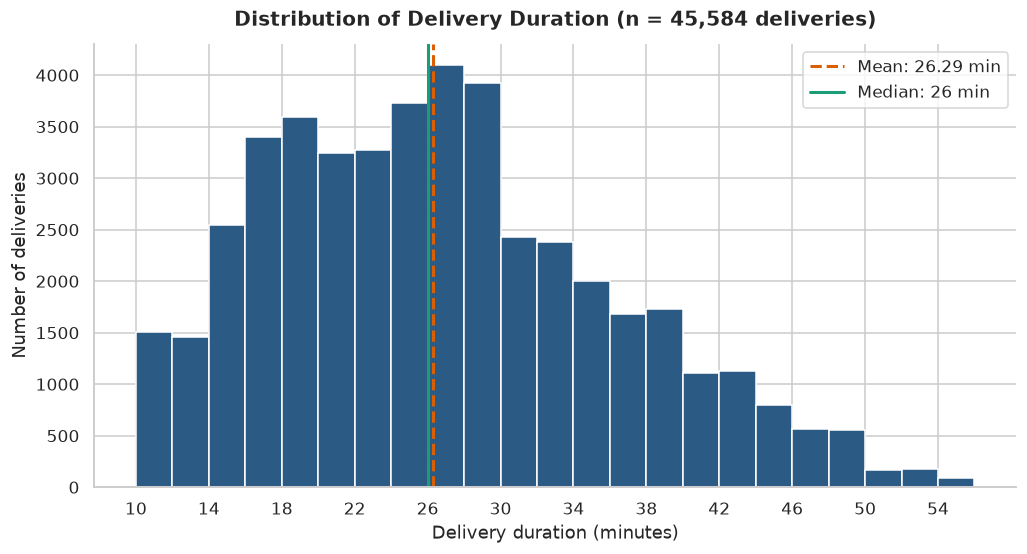

In [2]:
t = df[TARGET]
mean_v, median_v = t.mean(), t.median()
q1, q3 = t.quantile([.25, .75])
share_15_35 = ((t >= 15) & (t <= 35)).mean() * 100
n_45 = int((t >= 45).sum()); pct_45 = n_45 / len(t) * 100
skew = t.skew()

bins = np.arange(int(t.min()) // 2 * 2, int(t.max()) + 4, 2)          # 2-minute bins
counts, edges = np.histogram(t, bins=bins)
peak = counts.argmax(); peak_lo, peak_hi = int(edges[peak]), int(edges[peak + 1])
print(f"n={len(t):,} | mean={mean_v:.2f} | median={median_v:.0f} | Q1-Q3={q1:.0f}-{q3:.0f} | min-max={t.min()}-{t.max()} | skew={skew:.2f}")
print(f"15-35 min share: {share_15_35:.1f}% | >=45 min: {n_45:,} ({pct_45:.2f}%) | tallest bin: {peak_lo}-{peak_hi} min ({counts[peak]:,} deliveries)")

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.hist(t, bins=bins, color="#2B5B84", edgecolor="white")
ax.axvline(mean_v, color="#D95F02", ls="--", lw=2, label=f"Mean: {mean_v:.2f} min")
ax.axvline(median_v, color="#1B9E77", ls="-", lw=2, label=f"Median: {median_v:.0f} min")
ax.set_title(f"Distribution of Delivery Duration (n = {len(t):,} deliveries)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Delivery duration (minutes)"); ax.set_ylabel("Number of deliveries")
ax.set_xticks(np.arange(10, int(t.max()) + 2, 4)); ax.legend()
plt.tight_layout()
save_chart(fig, "01_delivery_duration_distribution.png")
plt.show()

### Interpretation — Chart 1
Most deliveries are concentrated in the middle of the range: 74.3% take 15–35 minutes, the middle half lies between 19 and 32 minutes, and the tallest bin is 26–28 minutes (4,097 deliveries). The shape is a broad hump with a mild right tail (skewness 0.49; mean 26.29 vs median 26 min), and the longest deliveries (1,803 orders, 3.96%, took 45–54 min) are plausible values and were kept as part of the tail. Limitation: this pools all cities, traffic and weather conditions, so it cannot show whether sub-groups have their own typical durations, and no delivery is recorded above 54 minutes.

## 3. Chart 2 — Traffic comparison (bar chart of median duration)
**What / why:** The median is used because it is not pulled by the long-delivery tail. Categories are ordered by traffic level and each bar is labelled with its median and group size. Rows with a missing traffic label are excluded and counted.

,count,median,mean,mean_distance_km
road_traffic_density,,,,
Low,15476,20.0,21.266671,8.149980
Medium,10945,27.0,26.699680,11.071411
High,4423,27.0,27.240109,4.397307
Jam,14139,31.0,31.176038,12.039551


Rows with missing traffic label (excluded): 601


Exported: ../visualizations/02_traffic_comparison.png


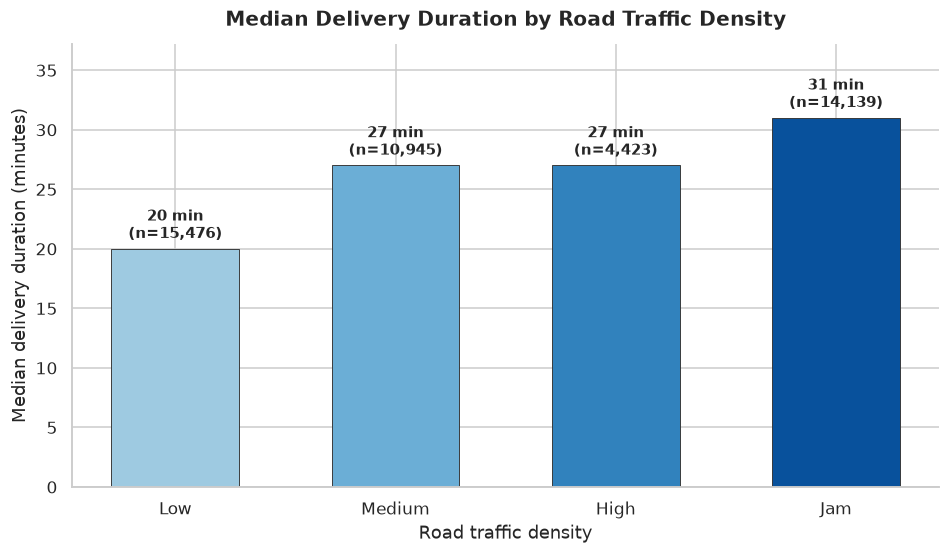

In [3]:
traffic_order = ["Low", "Medium", "High", "Jam"]
traffic_stats = (df.dropna(subset=["road_traffic_density"]).groupby("road_traffic_density")[TARGET]
                   .agg(count="count", median="median", mean="mean").reindex(traffic_order))
traffic_missing = int(df["road_traffic_density"].isna().sum())
traffic_dist = df.groupby("road_traffic_density")["distance_km"].mean().reindex(traffic_order)   # context for the limitation
display(traffic_stats.assign(mean_distance_km=traffic_dist))
print("Rows with missing traffic label (excluded):", traffic_missing)

fig, ax = plt.subplots(figsize=(8.8, 5.2))
bars = ax.bar(traffic_stats.index, traffic_stats["median"], color=["#9ECAE1", "#6BAED6", "#3182BD", "#08519C"],
              width=0.58, edgecolor="#333333", linewidth=0.6)
for bar, (_, r) in zip(bars, traffic_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{r['median']:.0f} min\n(n={int(r['count']):,})",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_title("Median Delivery Duration by Road Traffic Density", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Road traffic density"); ax.set_ylabel("Median delivery duration (minutes)")
ax.set_ylim(0, traffic_stats["median"].max() * 1.2)
plt.tight_layout()
save_chart(fig, "02_traffic_comparison.png")
plt.show()

### Interpretation — Chart 2
Median delivery time rises from 20 min in Low traffic (n=15,476) to 31 min in Jam (n=14,139), a gap of 11 minutes, while Medium (n=10,945) and High (n=4,423) share the same median of 27 min. Heavier traffic is therefore associated with slower deliveries, but this does not show that traffic alone causes the delay. Limitation: traffic groups also differ in typical distance (mean 8.1 km in Low, 4.4 km in High, 12.0 km in Jam), which may be why High is not slower than Medium, and 601 rows with no traffic label are excluded.

## 4. Chart 3 — Weather comparison (bar chart of average duration)
**What / why:** Compares the **mean** delivery duration across the six weather categories (as the brief requires), sorted from highest to lowest, with a dashed line for the overall mean so each bar can be judged against the baseline. Group sizes are shown on each bar; rows with a missing weather label are excluded.

,count,mean,median
weather_conditions,,,
Cloudy,7533,28.917164,28.0
Fog,7653,28.914674,28.0
Windy,7422,26.118836,26.0
Sandstorms,7494,25.875500,26.0
Stormy,7584,25.868803,26.0
Sunny,7282,21.856770,20.0


Rows with missing weather label (excluded): 616


Exported: ../visualizations/03_weather_comparison.png


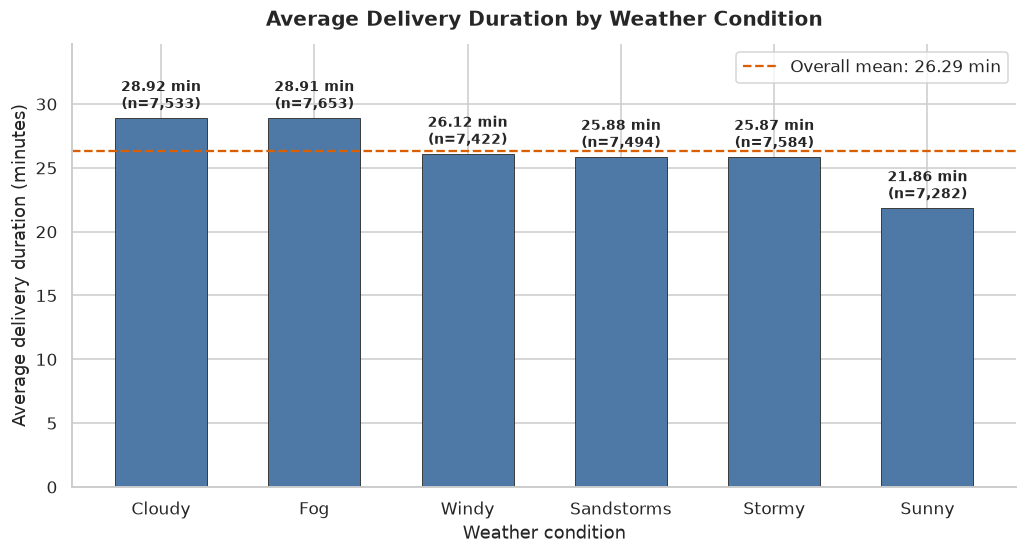

In [4]:
weather_stats = (df.dropna(subset=["weather_conditions"]).groupby("weather_conditions")[TARGET]
                   .agg(count="count", mean="mean", median="median").sort_values("mean", ascending=False))
weather_missing = int(df["weather_conditions"].isna().sum())
display(weather_stats)
print("Rows with missing weather label (excluded):", weather_missing)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
bars = ax.bar(weather_stats.index, weather_stats["mean"], color="#4E79A7", width=0.6, edgecolor="#333333", linewidth=0.6)
ax.axhline(mean_v, color="#D95F02", ls="--", lw=1.5, label=f"Overall mean: {mean_v:.2f} min")
for bar, (_, r) in zip(bars, weather_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"{r['mean']:.2f} min\n(n={int(r['count']):,})",
            ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_title("Average Delivery Duration by Weather Condition", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Weather condition"); ax.set_ylabel("Average delivery duration (minutes)")
ax.set_ylim(0, weather_stats["mean"].max() * 1.2); ax.legend(loc="upper right")
plt.tight_layout()
save_chart(fig, "03_weather_comparison.png")
plt.show()

### Interpretation — Chart 3
Average delivery time is highest in Cloudy (28.92 min, n=7,533) and Fog (28.91 min, n=7,653), middling for Windy, Sandstorms and Stormy (25.87–26.12 min), and lowest in Sunny (21.86 min, n=7,282), about 7.1 minutes below the highest. This suggests that Cloudy and Fog conditions coincide with slower deliveries, but weather may overlap with traffic, city or season, so the gap is not proof of a weather effect. Limitation: weather is a single label per order with no severity or rainfall measure, 616 rows with no weather label are excluded, and means can be pulled up by long deliveries.

## 5. Chart 4 — Distance vs delivery duration (scatter plot)
**What / why:** Shows the direction and strength of the relationship between straight-line distance and delivery time. Low point opacity limits overplotting, a linear trend line shows the average direction, and two kinds of unusual points are highlighted: **short but slow** trips (under 5 km and 45 min or more) and **long but fast** trips (over 15 km and 20 min or less). Rows without a valid distance are excluded.

n=41,944 | distance range 1.47-20.97 km
Pearson r=0.320 | Spearman rho=0.319 | r^2=0.103 | slope=0.54 min/km
Short & slow: 123 of 11,300 trips under 5 km | Long & fast: 1,605 of 8,046 trips over 15 km


Exported: ../visualizations/04_distance_vs_duration.png


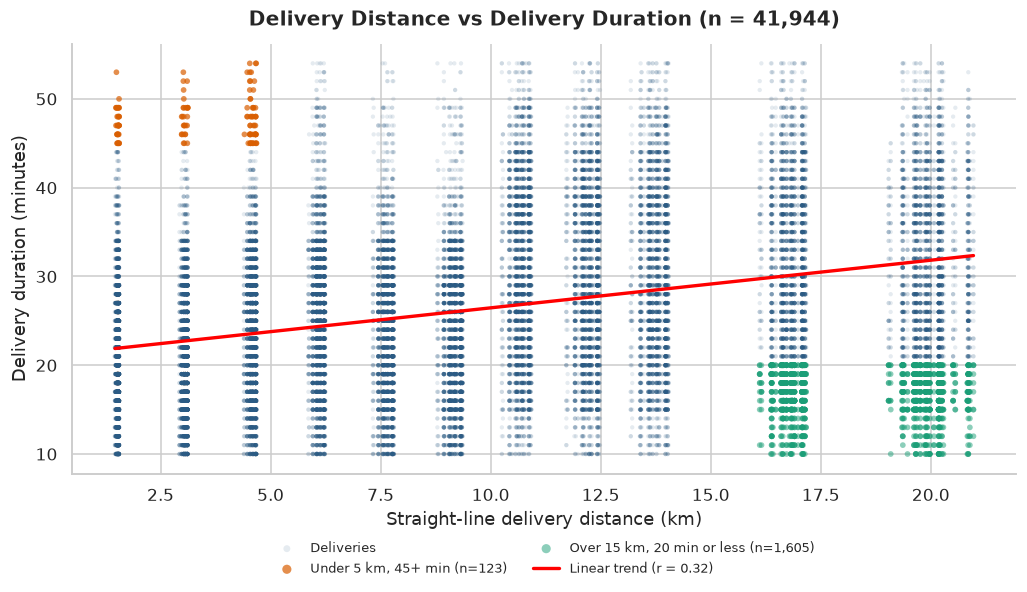

In [5]:
d = df.dropna(subset=["distance_km", TARGET])
pearson = d["distance_km"].corr(d[TARGET])
spearman = d["distance_km"].corr(d[TARGET], method="spearman")
slope, intercept = np.polyfit(d["distance_km"], d[TARGET], 1)

short_slow = (d["distance_km"] < 5) & (d[TARGET] >= 45)
long_fast = (d["distance_km"] > 15) & (d[TARGET] <= 20)
n_short, n_long = int((d["distance_km"] < 5).sum()), int((d["distance_km"] > 15).sum())
print(f"n={len(d):,} | distance range {d.distance_km.min():.2f}-{d.distance_km.max():.2f} km")
print(f"Pearson r={pearson:.3f} | Spearman rho={spearman:.3f} | r^2={pearson**2:.3f} | slope={slope:.2f} min/km")
print(f"Short & slow: {int(short_slow.sum())} of {n_short:,} trips under 5 km | Long & fast: {int(long_fast.sum()):,} of {n_long:,} trips over 15 km")

fig, ax = plt.subplots(figsize=(9.5, 5.6))
rest = ~(short_slow | long_fast)
ax.scatter(d.loc[rest, "distance_km"], d.loc[rest, TARGET], s=8, alpha=0.12, color="#2B5B84", edgecolors="none", label="Deliveries")
ax.scatter(d.loc[short_slow, "distance_km"], d.loc[short_slow, TARGET], s=14, alpha=0.7, color="#D95F02", edgecolors="none",
           label=f"Under 5 km, 45+ min (n={int(short_slow.sum())})")
ax.scatter(d.loc[long_fast, "distance_km"], d.loc[long_fast, TARGET], s=14, alpha=0.5, color="#1B9E77", edgecolors="none",
           label=f"Over 15 km, 20 min or less (n={int(long_fast.sum()):,})")
xs = np.linspace(d.distance_km.min(), d.distance_km.max(), 100)
ax.plot(xs, intercept + slope * xs, color="red", lw=2.2, label=f"Linear trend (r = {pearson:.2f})")
ax.set_title(f"Delivery Distance vs Delivery Duration (n = {len(d):,})", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Straight-line delivery distance (km)"); ax.set_ylabel("Delivery duration (minutes)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8.5, markerscale=1.6, frameon=False)   # legend below the plot so it hides no points
plt.tight_layout()
save_chart(fig, "04_distance_vs_duration.png")
plt.show()

### Interpretation — Chart 4
Longer distances are associated with longer deliveries, but only weakly to moderately (Pearson r = 0.320, Spearman ρ = 0.319, n = 41,944); the trend adds about 0.54 minutes per km and distance explains only 10.3% of the variation, so traffic, load and other factors matter more. Unusual points are common among long trips: 1,605 of 8,046 trips over 15 km (20%) finished in 20 minutes or less, while only 123 of 11,300 trips under 5 km took 45 minutes or more. Limitation: distance is a straight-line estimate, not road distance, the points form vertical stripes because distances take a limited set of values, and 3,640 rows with placeholder coordinates are excluded.

## 6. Chart 5 — Vehicle comparison (box plot)
**What / why:** A box plot compares the whole duration distribution per vehicle type: the line inside each box is the median, the box is the interquartile range (IQR), whiskers extend to 1.5×IQR, and points beyond are plotted outliers. Vehicles are ordered by group size so the very small `bicycle` group is clearly flagged at the end; medians are printed on the chart.

,count,median,q1,q3,mean,outliers,iqr
type_of_vehicle,,,,,,,
motorcycle,26429,26.0,20.0,34.00,27.605774,0,14.00
scooter,15273,24.0,17.0,30.00,24.478819,3,13.00
electric_scooter,3814,24.0,17.0,30.00,24.470110,1,13.00
bicycle,68,26.0,19.0,32.25,26.426471,0,13.25


Exported: ../visualizations/05_vehicle_comparison.png


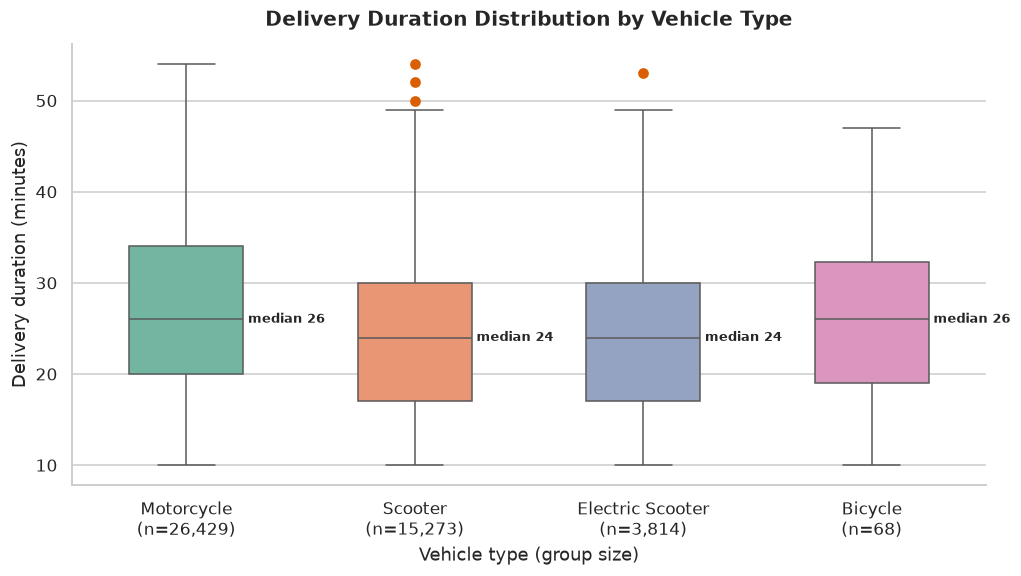

In [6]:
vehicle_order = df["type_of_vehicle"].value_counts().index.tolist()          # largest group first
def n_outliers(s):
    a, b = s.quantile([.25, .75]); i = b - a
    return int(((s < a - 1.5 * i) | (s > b + 1.5 * i)).sum())

g = df.groupby("type_of_vehicle")[TARGET]
veh_stats = pd.DataFrame({"count": g.count(), "median": g.median(), "q1": g.quantile(.25), "q3": g.quantile(.75),
                          "mean": g.mean(), "outliers": g.apply(n_outliers)}).reindex(vehicle_order)
veh_stats["iqr"] = veh_stats["q3"] - veh_stats["q1"]
display(veh_stats)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
sns.boxplot(data=df, x="type_of_vehicle", y=TARGET, order=vehicle_order, hue="type_of_vehicle", hue_order=vehicle_order,
            palette="Set2", legend=False, width=0.5, showfliers=True,
            flierprops={"marker": "o", "markersize": 6, "markerfacecolor": "#D95F02", "markeredgecolor": "#D95F02"}, ax=ax)
ax.set_xticks(range(len(vehicle_order)))
ax.set_xticklabels([f"{v.replace('_', ' ').title()}\n(n={int(veh_stats.loc[v, 'count']):,})" for v in vehicle_order])
for i, v in enumerate(vehicle_order):
    ax.text(i + 0.27, veh_stats.loc[v, "median"], f"median {veh_stats.loc[v, 'median']:.0f}", va="center", fontsize=8.5, fontweight="bold")
ax.set_title("Delivery Duration Distribution by Vehicle Type", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Vehicle type (group size)"); ax.set_ylabel("Delivery duration (minutes)")
plt.tight_layout()
save_chart(fig, "05_vehicle_comparison.png")
plt.show()

### Interpretation — Chart 5
Motorcycle deliveries (n=26,429) have a median of 26 min and IQR 20–34 min (width 14), compared with a median of 24 min and IQR 17–30 (width 13) for both scooter (n=15,273) and electric scooter (n=3,814), so scooters are typically about 2 minutes faster. The boxes overlap heavily, so vehicle type separates delivery times only slightly. Limitation: bicycle has only 68 deliveries, only 4 outlier points are plotted in total (durations stop at 54 min), and the chart does not control for traffic, load or area.

## 7. Export verification
**What / why:** Confirm that all five PNG files exist, are non-empty and can be re-opened as images, so reviewers can view them on GitHub.

In [7]:
import matplotlib.image as mpimg
expected = ["01_delivery_duration_distribution.png", "02_traffic_comparison.png", "03_weather_comparison.png",
            "04_distance_vs_duration.png", "05_vehicle_comparison.png"]
rows = []
for f in expected:
    p = os.path.join(VIZ_DIR, f)
    assert os.path.exists(p) and os.path.getsize(p) > 0, f"Missing or empty: {p}"
    img = mpimg.imread(p)                                          # raises an error if the PNG cannot be read
    rows.append({"file": f, "size_kb": round(os.path.getsize(p) / 1024, 1), "pixels (h x w)": f"{img.shape[0]} x {img.shape[1]}"})
display(pd.DataFrame(rows))
print("All 5 charts exported and readable.")

,file,size_kb,pixels (h x w)
0,01_delivery_duration_distribution.png,57.1,756 x 1400
1,02_traffic_comparison.png,56.4,756 x 1295
2,03_weather_comparison.png,77.7,756 x 1400
3,04_distance_vs_duration.png,352.4,806 x 1400
4,05_vehicle_comparison.png,63.7,785 x 1394


All 5 charts exported and readable.


## 8. Summary of limitations (carried into Week 4)
- All patterns are **associations**; traffic, weather, distance, vehicle and delivery load overlap with one another.
- Distance is **straight-line**, and rows with placeholder coordinates have no distance.
- Rows with a missing traffic or weather label are excluded from those charts, not imputed.
- Small groups (`bicycle`) and very capped durations (maximum 54 minutes) limit what the box plot can show.
- Week 4 will turn these findings into operational recommendations and the final report.